## how to use this notebook

this notebook implements **System 1** (cosine similarity) in the pooled evaluation pipeline for filtering
social-policy legislation from a retrieved corpus. System 2 (berttopic modeling) is
in `step2_2_1_process_ger_berttopic.py` and `step2_2_2_process_ger_berttopic_triage.py`; the union of both systems is compiled in
`step3_process_pooled_union_compile.py`.

it is a reusable pipeline step that filters a raw legislative text dataset down to
social-policy relevant documents using cosine similarity between document title embeddings and
policy-field seed descriptions.

**to process a new dataset:**

1. set `INPUT_FILE` in the **configuration** cell below to your raw `.json` file
   (format: a JSON list of objects, each with at least a `"title"` field)
2. set `OUTPUT_DIR` to the folder where results should be saved
3. set `OUTPUT_PREFIX` to a short label for your run — used to name output files (e.g. `"germany_cov"`)
4. run the scouting section (§1) and the score-distribution plot (§2) to inspect your data
5. adjust `AUTO_THRESHOLD` and `BORDERLINE_LOW` based on the score distribution:
   - documents scoring ≥ `AUTO_THRESHOLD` → auto-accepted (high confidence)
   - documents scoring ≥ `BORDERLINE_LOW` but < `AUTO_THRESHOLD` → manual triage via `step4_process_triage_germany_borderline.py`
   - documents scoring below `BORDERLINE_LOW` → discarded
6. run the saving section (§2.2) to write the output files

**seed descriptions** (imported from `step2_1_1_process_ger_cosinesim_seed_descriptions.py`) define the
policy domain you are filtering for. to filter for a different domain, replace or extend
`ALL_SEEDS` in that file.

**outputs saved to `OUTPUT_DIR`:**
- `{OUTPUT_PREFIX}_cosinesim_auto_accepted.json` — high-confidence matches, ready for LLM classification
- `{OUTPUT_PREFIX}_cosinesim_borderline_candidates.json` — borderline matches, needs manual triage

# step 2.1: pooled evaluation — system 1: cosine similarity



In [1]:
# pip installs:
##pip install sentence-transformers

#imports:

##imports for reading data
import json
import gzip
##imports for 2.1 filtering approach 1:

import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
import numpy as np
from step2_1_1_process_ger_cosinesim_seed_descriptions import ALL_SEEDS #these are seed descriptions of social policy fields I created based on a bmas publication under "policy-tracker/data/external/bmas_soziale-sicherung-im-ueberblick.pdf"
from sklearn.metrics.pairwise import cosine_similarity

##imports to save filtered and processed raw texts

from pathlib import Path

##imports for log file

import datetime, os, stat


In [2]:
# ── CONFIGURATION — set these before running ────────────────────────────────

def _find_root(marker="CLAUDE.md"):
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / marker).exists():
            return p
    raise FileNotFoundError(f"project root not found (no {marker} above {Path.cwd()})")

PROJECT_ROOT = _find_root()

INPUT_FILE    = PROJECT_ROOT / "data/raw/germany/bgbl1_2016-2018_20260918.json"
OUTPUT_DIR    = PROJECT_ROOT / "data/processed/germany/pre2023"
OUTPUT_PREFIX = "germany_2016-2018"   # prefix for output filenames (IMPORTANT!)


print(f"Project root: {PROJECT_ROOT}")

# ────────────────────────────────────────────────────────────────────────────

Project root: s:\stbuchho\crises_and_welfare_states\policy-tracker


## 1. scouting raw data

In [3]:
opener = gzip.open if Path(INPUT_FILE).suffix == ".gz" else open
with opener(INPUT_FILE, "rt", encoding="utf-8") as file:
    data = json.load(file)

entries = data if isinstance(data, list) else list(data.values())
for i, entry in enumerate(entries[:10]):
    print(f"--- Entry {i+1} ---")
    print(json.dumps(entry, ensure_ascii=False, indent=2))

--- Entry 1 ---
{
  "id": "bgbl1-2016-67-1",
  "year": 2016,
  "issue_number": 67,
  "order_in_issue": 1,
  "title": "Gesetz zur Ausland-Ausland-Fernmeldeaufklärung des Bundesnachrichtendienstes",
  "doc_type": "Gesetz",
  "date_published": "2016-12-30T00:00:00Z",
  "date_law": "2016-12-23T00:00:00Z",
  "bgbl_page": 3346,
  "pdf_page": 2,
  "num_pages": 8,
  "url_web": "https://offenegesetze.de/veroeffentlichung/bgbl1/2016/67#page=2",
  "url_api": "https://api.offenegesetze.de/v1/veroeffentlichung/bgbl1-2016-67-1/",
  "url_pdf": "https://media.offenegesetze.de/bgbl1/2016/bgbl1_2016_67.pdf#page=2",
  "full_text": "3346           Bundesgesetzblatt Jahrgang 2016 Teil I Nr. 67, ausgegeben zu Bonn am 30. Dezember 2016\nGesetz\nzur Ausland-Ausland-Fernmeldeaufklärung des Bundesnachrichtendienstes\nVom 23. Dezember 2016\nDer Bundestag hat das folgende Gesetz beschlos-                   (2) Der Bundesnachrichtendienst darf die Erhe-\nsen:                                                        

## 2. filtering

goal: this section filters social-policy relevant titles from the entire entire retrieved body of raw legal text data (for Germany: Gesetze, REchtsverordnungen, Bekanntmachungen). 

approach: it utilizes cosine similarities between the embeddings of titles of these documents and policy-field seed descriptions that were constructed in step1_process_ger_seed_desc_covid and step2_1_1_process_ger_cosinesim_seed_descriptions.py. for the embeddings the German-suited sentence transformer "paraphrase-multilingual-mpnet-base-v2" is used.

decision: legal text documents with high cosine similarities to the seed descriptions are selected and stored.

In [4]:

#create object for transformer model
model = SentenceTransformer("paraphrase-multilingual-mpnet-base-v2")

#embed seeds
seed_embeddings = model.encode(ALL_SEEDS, show_progress_bar=True)

#embed legal documents via titles
titles=[doc["title"] for doc in data]
doc_embeddings = model.encode(titles, batch_size=16, show_progress_bar=True)

#cosine similarity: for each doc, max similarity across all seeds
sim_matrix = cosine_similarity(doc_embeddings, seed_embeddings) # shape: rows are docs, columns are seeds
max_scores = sim_matrix.max(axis=1) #collapses each row to its highest value (the seed that matched the doc best)

print(f"Score range: {max_scores.min():.3f} – {max_scores.max():.3f}")
print(f"Mean: {max_scores.mean():.3f}, Median: {np.median(max_scores):.3f}")


Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Batches:   0%|          | 0/73 [00:00<?, ?it/s]

Score range: 0.413 – 0.906
Mean: 0.648, Median: 0.640


interpretation score range: cosine similarity scores range from 0.373 - 0.966 -> suggests that there is a real signal to work with here for filtering


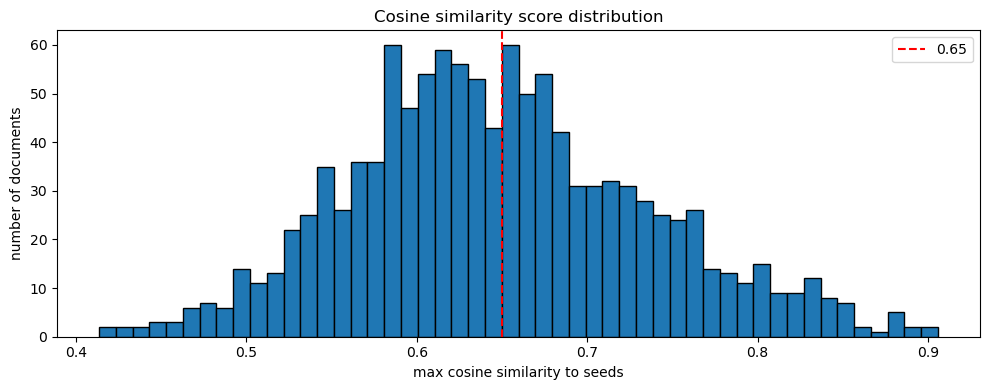

In [5]:
# distribution of cosine-similarity scores between documents and the seed descriptions

fig_scores, ax_scores = plt.subplots(figsize=(10, 4))
ax_scores.hist(max_scores, bins=50, edgecolor="black")
ax_scores.set_xlabel("max cosine similarity to seeds")
ax_scores.set_ylabel("number of documents")
ax_scores.set_title("Cosine similarity score distribution")
ax_scores.axvline(x=0.65, color="red", linestyle="--", label="0.65")
ax_scores.legend()
fig_scores.tight_layout()
plt.show()

visual investigation of the distribution of cosine similarity scores : can we identify a normal distribution for the (ideally so, because there is legislation that is social policy related (few) and such that is not (majority)? are cut-off values of scores detectable?

if no cut-off values are detectable (most likely case), then the following step creates lists of policy text titles along certain cut-offs

In [6]:
scored = sorted(zip(max_scores, data), key=lambda x: x[0], reverse=True)

print("=== TOP 10 ===")
for score, doc in scored[:30]:
    print(f"  {score:.3f}  {doc['title'][:150]}")

print("\n=== ABOVE 0.73 ===")
for score, doc in scored:
    if  score > 0.73:
        print(f"  {score:.3f}  {doc['title'][:150]}") 


print("\n=== AROUND 0.70 ===")
for score, doc in scored:
    if 0.69 < score < 0.71:
        print(f"  {score:.3f}  {doc['title'][:100]}")   


print("\n=== BOTTOM 10 ===")
for score, doc in scored[-10:]:
    print(f"  {score:.3f}  {doc['title'][:100]}")

=== TOP 10 ===
  0.906  Verordnung zur Änderung der Mindestlohnmeldeverordnung
  0.898  Gesetz zur Beitragsentlastung der Versicherten in der gesetzlichen Krankenversicherung (GKV-Versichertenentlastungsgesetz  GKV-VEG)
  0.895  Verordnung zur Anpassung der Höhe des Mindestlohns (Mindestlohnanpassungsverordnung  MiLoV)
  0.890  Verordnung über die pauschalierten Nettoentgelte für das Kurzarbeitergeld für das Jahr 2017
  0.885  Verordnung über die pauschalierten Nettoentgelte für das Kurzarbeitergeld für das Jahr 2019
  0.884  Verordnung über die pauschalierten Nettoentgelte für das Kurzarbeitergeld für das Jahr 2018
  0.882  Zweite Verordnung zur Anpassung der Höhe des Mindestlohns (Zweite Mindestlohnanpassungsverordnung  MiLoV2)
  0.880  Gesetz zur Einführung beschleunigter Asylverfahren
  0.878  Gesetz zur steuerlichen Entlastung der Familien sowie zur Anpassung weiterer steuerlicher Regelungen (Familienentlastungsgesetz  FamEntlastG)
  0.871  Verordnung zur Gleichstellung von Pr

results: the visual inspection serves the identification of an auto-threshold above which policy documents are auto-accepted and a borderline-low below which policies are auto-rejected. between those threshholds, a human manual triage is conducted in step4


In [7]:
# ── CONFIGURATION — set these before running ────────────────────────────────
AUTO_THRESHOLD = 0.765  # cosine similarity >= this → auto-accepted
BORDERLINE_LOW = 0.735    # cosine similarity >= this but < AUTO_THRESHOLD → manual triage


## 2.2 saving the final .json

this section saves two output files. thresholds are set in the configuration cell above — adjust them
based on the score distribution plots in the previous section.

- documents scoring ≥ `AUTO_THRESHOLD` are written to `{OUTPUT_PREFIX}_cosinesim_auto_accepted.json`
- documents scoring ≥ `BORDERLINE_LOW` but below `AUTO_THRESHOLD` are written to `{OUTPUT_PREFIX}_cosinesim_borderline_candidates.json` for individual manual inspection with the triage tool in `step4_process_triage_germany_borderline.py`

In [8]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

auto_accepted = []
borderline = []

for score, doc in scored:
    entry = {**doc, "similarity_score": float(score)}
    if score >= AUTO_THRESHOLD:
        auto_accepted.append(entry)
    elif score >= BORDERLINE_LOW:
        borderline.append(entry)

print(f"Auto-accepted (>= {AUTO_THRESHOLD}):                {len(auto_accepted)}")
print(f"Borderline ({BORDERLINE_LOW}–{AUTO_THRESHOLD - 0.001:.3f}, needs manual triage): {len(borderline)}")
print(f"Below threshold (< {BORDERLINE_LOW}):               {len(scored) - len(auto_accepted) - len(borderline)}")

auto_path       = OUTPUT_DIR / f"{OUTPUT_PREFIX}_cosinesim_auto_accepted.json"
borderline_path = OUTPUT_DIR / f"{OUTPUT_PREFIX}_cosinesim_borderline_candidates.json"

auto_path.write_text(json.dumps(auto_accepted, ensure_ascii=False, indent=2), encoding="utf-8")
borderline_path.write_text(json.dumps(borderline, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"\nSaved: {auto_path}")
print(f"Saved: {borderline_path}")


Auto-accepted (>= 0.765):                120
Borderline (0.735–0.764, needs manual triage): 75
Below threshold (< 0.735):               970

Saved: s:\stbuchho\crises_and_welfare_states\policy-tracker\data\processed\germany\pre2023\germany_2016-2018_cosinesim_auto_accepted.json
Saved: s:\stbuchho\crises_and_welfare_states\policy-tracker\data\processed\germany\pre2023\germany_2016-2018_cosinesim_borderline_candidates.json


## 3. run log

saves a read-only markdown log to `data/processed/{country}/pre2023/runlogs_from_sys1_seeddes/`. the filename encodes the dataset and run date so each run produces a distinct, non-overwritable record.

In [10]:


run_date   = datetime.date.today().isoformat()
input_stem = Path(INPUT_FILE).name.removesuffix(".gz").removesuffix(".json")
log_dir    = OUTPUT_DIR / "runlogs_from_sys1_seeddes"
log_dir.mkdir(parents=True, exist_ok=True)

log_stem = f"filter_runlog_{OUTPUT_PREFIX}_{input_stem}_{run_date}"
log_path = log_dir / f"{log_stem}.md"
png_name = f"{log_stem}_scores.png"
png_path = log_dir / png_name

# strip read-only if files exist from a same-day re-run
for p in (png_path, log_path):
    if p.exists():
        os.chmod(p, stat.S_IWRITE)

fig_scores.savefig(png_path, dpi=150, bbox_inches="tight")
os.chmod(png_path, stat.S_IREAD | stat.S_IRGRP | stat.S_IROTH)

content = f"""# filter run log

| | |
|---|---|
| date | {run_date} |
| input file | `{INPUT_FILE}` |
| output dir | `{OUTPUT_DIR}` |
| output prefix | `{OUTPUT_PREFIX}` |

## configuration

| parameter | value |
|---|---|
| AUTO_THRESHOLD | {AUTO_THRESHOLD} |
| BORDERLINE_LOW | {BORDERLINE_LOW} |

## score distribution

| metric | value |
|---|---|
| min | {max_scores.min():.3f} |
| max | {max_scores.max():.3f} |
| mean | {max_scores.mean():.3f} |
| median | {np.median(max_scores):.3f} |

![score distribution]({png_name})

## filtering results

| category | n |
|---|---|
| auto-accepted (>= {AUTO_THRESHOLD}) | {len(auto_accepted)} |
| borderline ({BORDERLINE_LOW}–{AUTO_THRESHOLD - 0.001:.3f}) | {len(borderline)} |
| below threshold (< {BORDERLINE_LOW}) | {len(scored) - len(auto_accepted) - len(borderline)} |
| total | {len(scored)} |

## output files

- `{auto_path}`
- `{borderline_path}`
"""

log_path.write_text(content, encoding="utf-8")
os.chmod(log_path, stat.S_IREAD | stat.S_IRGRP | stat.S_IROTH)
print(f"Run log saved (read-only): {log_path}")
print(f"Score plot saved (read-only): {png_path}")


print("\nNext: run step2_1_4_process_ger_cosinesim_triage_borderline.py to review borderline cases.")

Run log saved (read-only): s:\stbuchho\crises_and_welfare_states\policy-tracker\data\processed\germany\pre2023\runlogs_from_sys1_seeddes\filter_runlog_germany_2016-2018_bgbl1_2016-2018_20260918_2026-10-16.md
Score plot saved (read-only): s:\stbuchho\crises_and_welfare_states\policy-tracker\data\processed\germany\pre2023\runlogs_from_sys1_seeddes\filter_runlog_germany_2016-2018_bgbl1_2016-2018_20260918_2026-10-16_scores.png

Next: run step2_1_4_process_ger_cosinesim_triage_borderline.py to review borderline cases.
